## Lecture 4 — Pre-attentive Attributes +  Scatter & Bubble Charts


> **Dataset:** Gapminder — GDP per capita, Life Expectancy, Population. Source: Gapminder Foundation ([gapminder.org](https://www.gapminder.org/))

> **Source of figures:** Knaflic, C. N. (2015). *Storytelling with data*. Wiley.


## Model Answer Review From Week 03

---
## Design Principles - Part I: Pre-attentive Attributes


Chapter 4 of *Storytelling with Data* ("Focus your audience's attention") describes three types of memory:

- **Iconic memory:** very fast and automatic, holding what we see for only a fraction of a second. Preattentive attributes like colour, size and position are processed here, which is why a well-placed highlight is noticed before the viewer consciously looks for it.
- **Short-term memory:** limited to about four chunks of visual information at a time. This is why a chart with many separate pieces, such as a long legend the reader must match to lines, overloads the audience. Direct labelling and fewer elements help.
- **Long-term memory:** built up over a lifetime and where we want our message to end up. Knaflic links it to combining visuals with words, so that a picture and a clear story or takeaway reinforce each other and make the point memorable.

### You see with your brain, not just your eyes

> 💡 **Iconic memory processes your visual field before you consciously see anything — within 250 milliseconds. Preattentive attributes act at this level. When we use them correctly, we can make the audience see exactly what we want before they even realise they are looking**


*Count the 3s — no visual cues: requires slow conscious search*

> 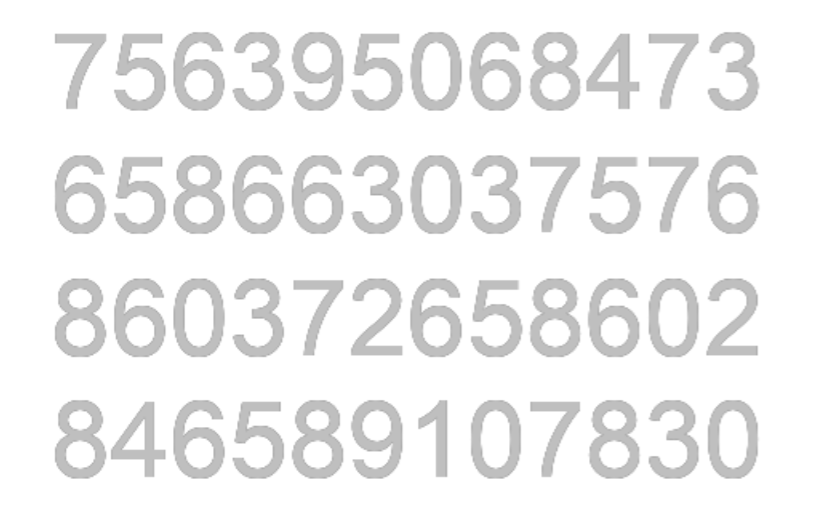 



*Count the 3s with colour highlight — the 3s jump out instantly (iconic memory)*

> 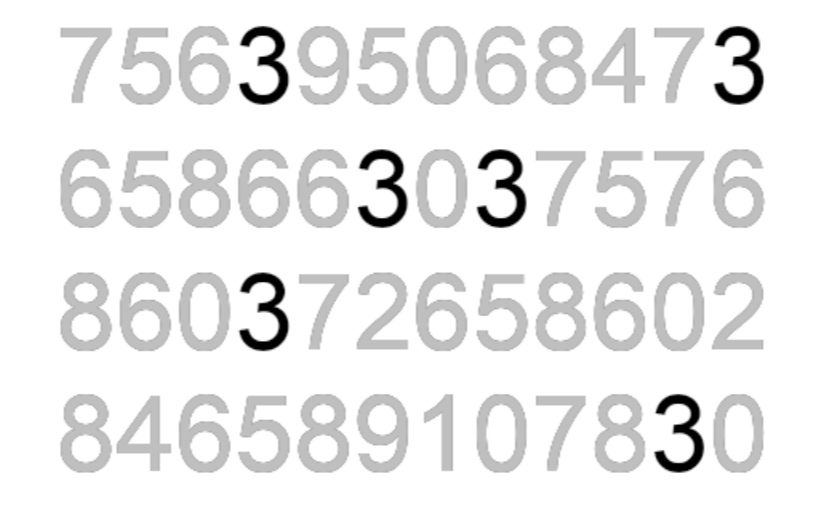 

---

### All pre-attentive attributes illustrated: colour, size, orientation, shape, added marks

**Used sparingly in a chart, they offer two benefits:**

1. **Direct your audience's attention:** a single highlight colour, bold text or a heavier line makes the eye go straight to the part that matters, so viewers see what you want them to see before they consciously search the chart.

2. **Create a visual hierarchy:** by making the most important elements stand out and pushing the rest into the background (for example in grey), you set the order in which the information is read. The viewer gets the key message first, then the supporting context.

> 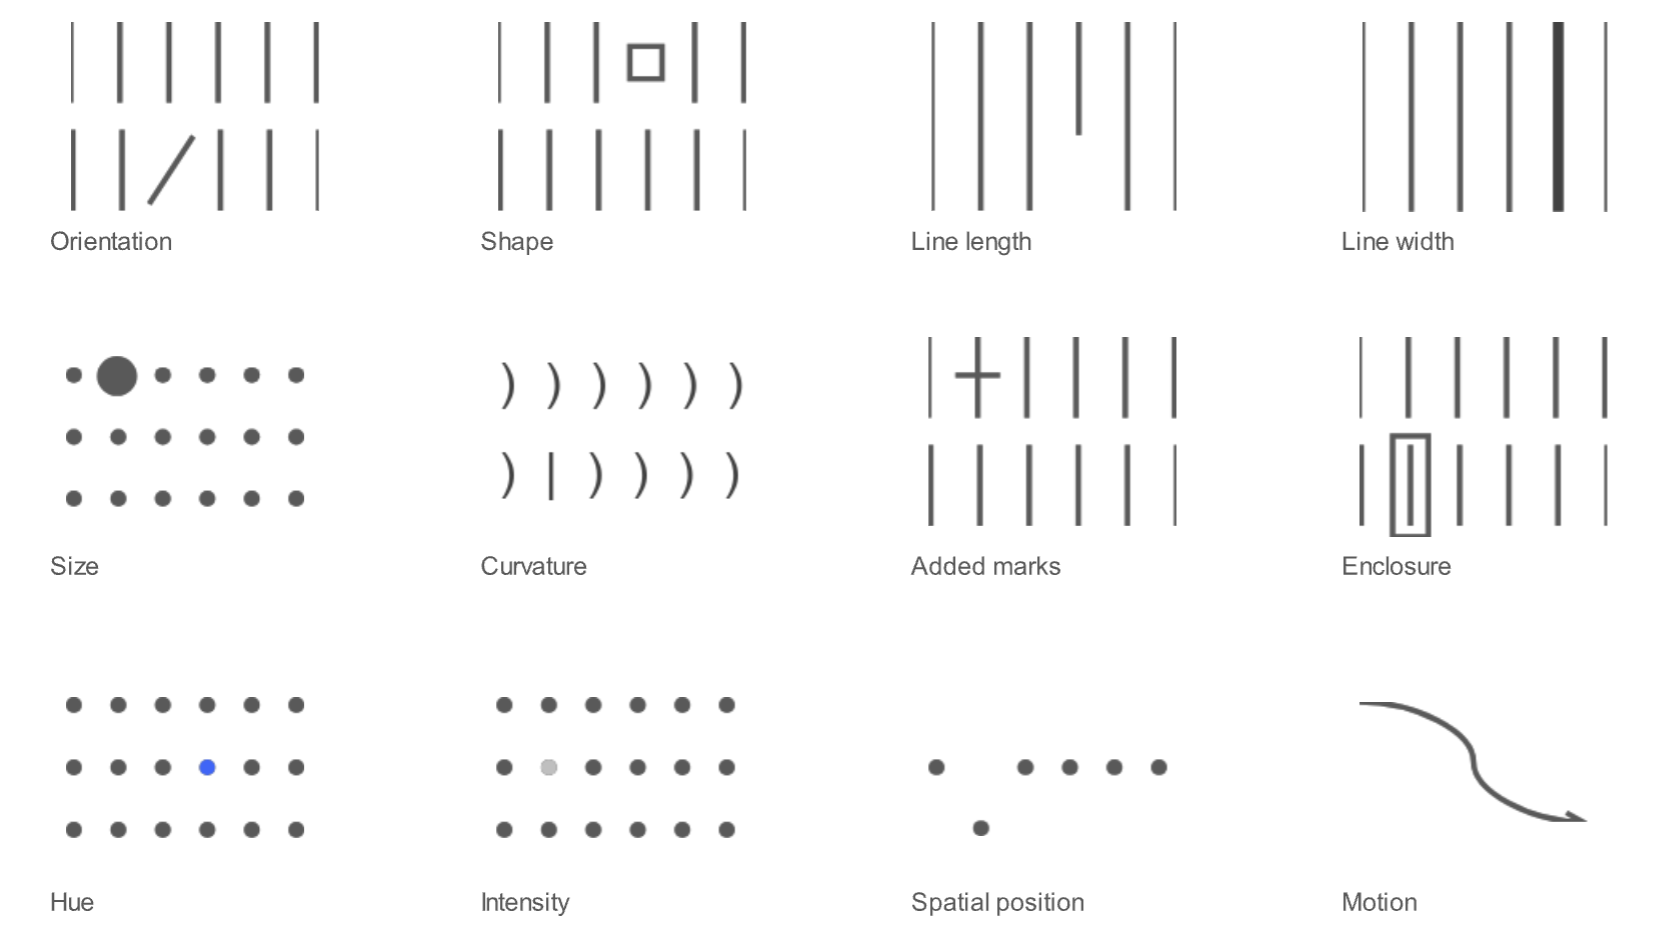  


**Example:**
*Using no pre-attentive attributes*
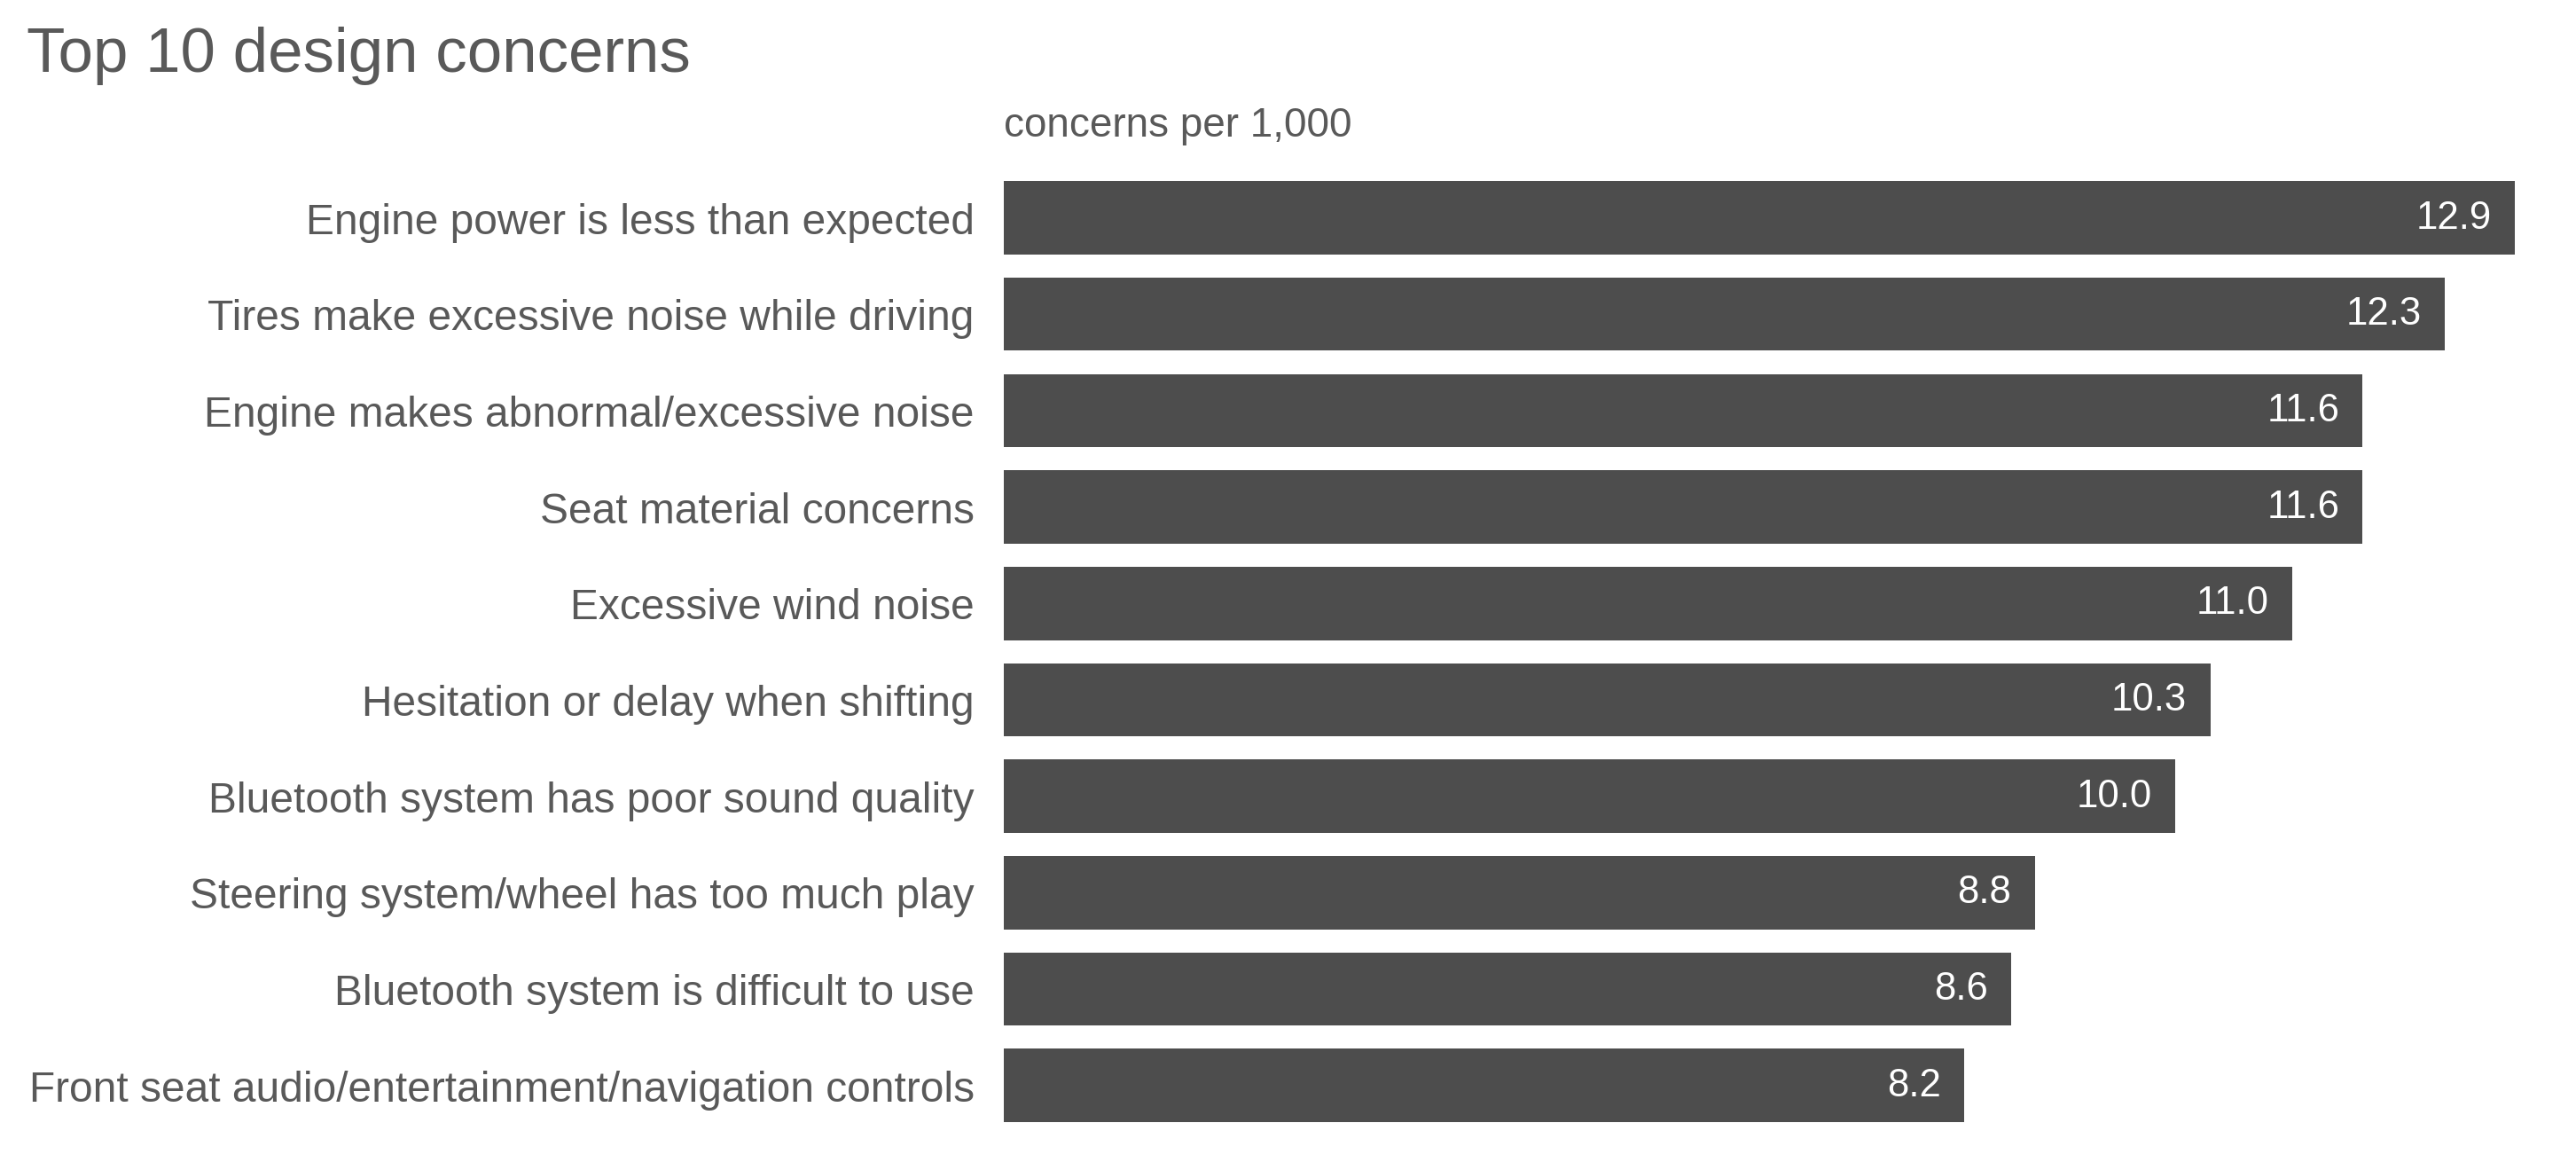 

*Using color as a pre-attentive attribute to capture audience attention to a specific story*
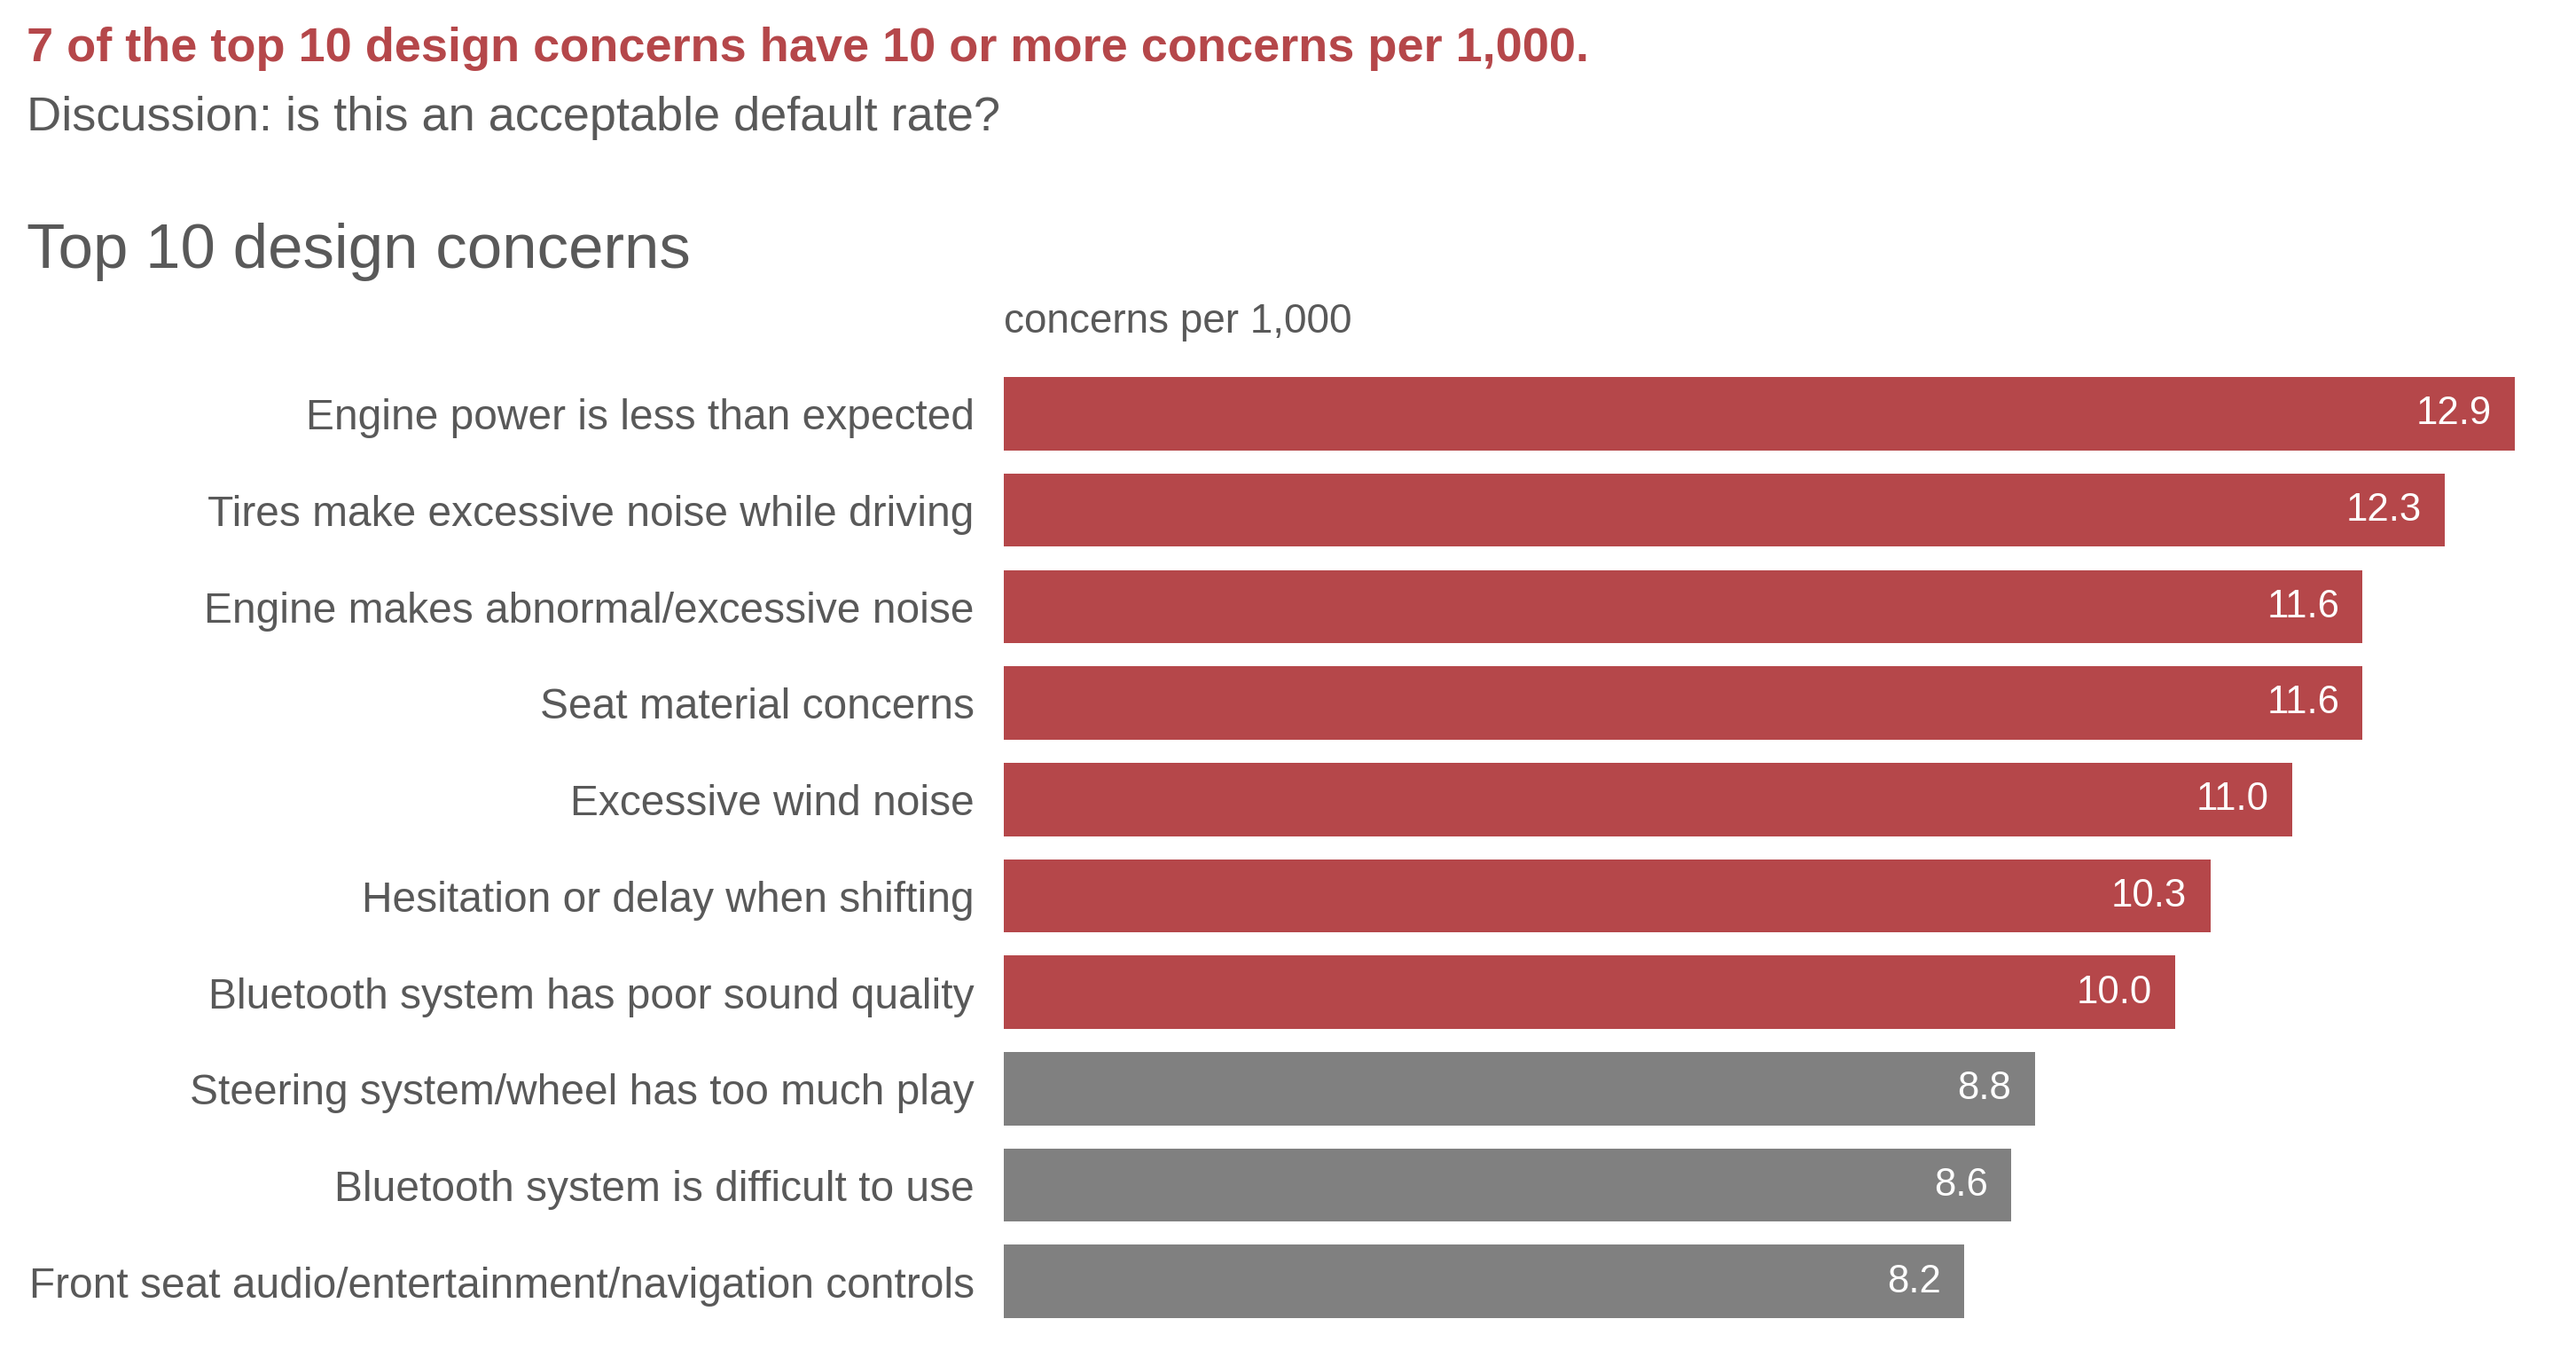 

*Using color and intensity as pre-attentive attributes to achieve to additionally add hierarchy, i.e. lead audience focus to macro and micro parts of the story*
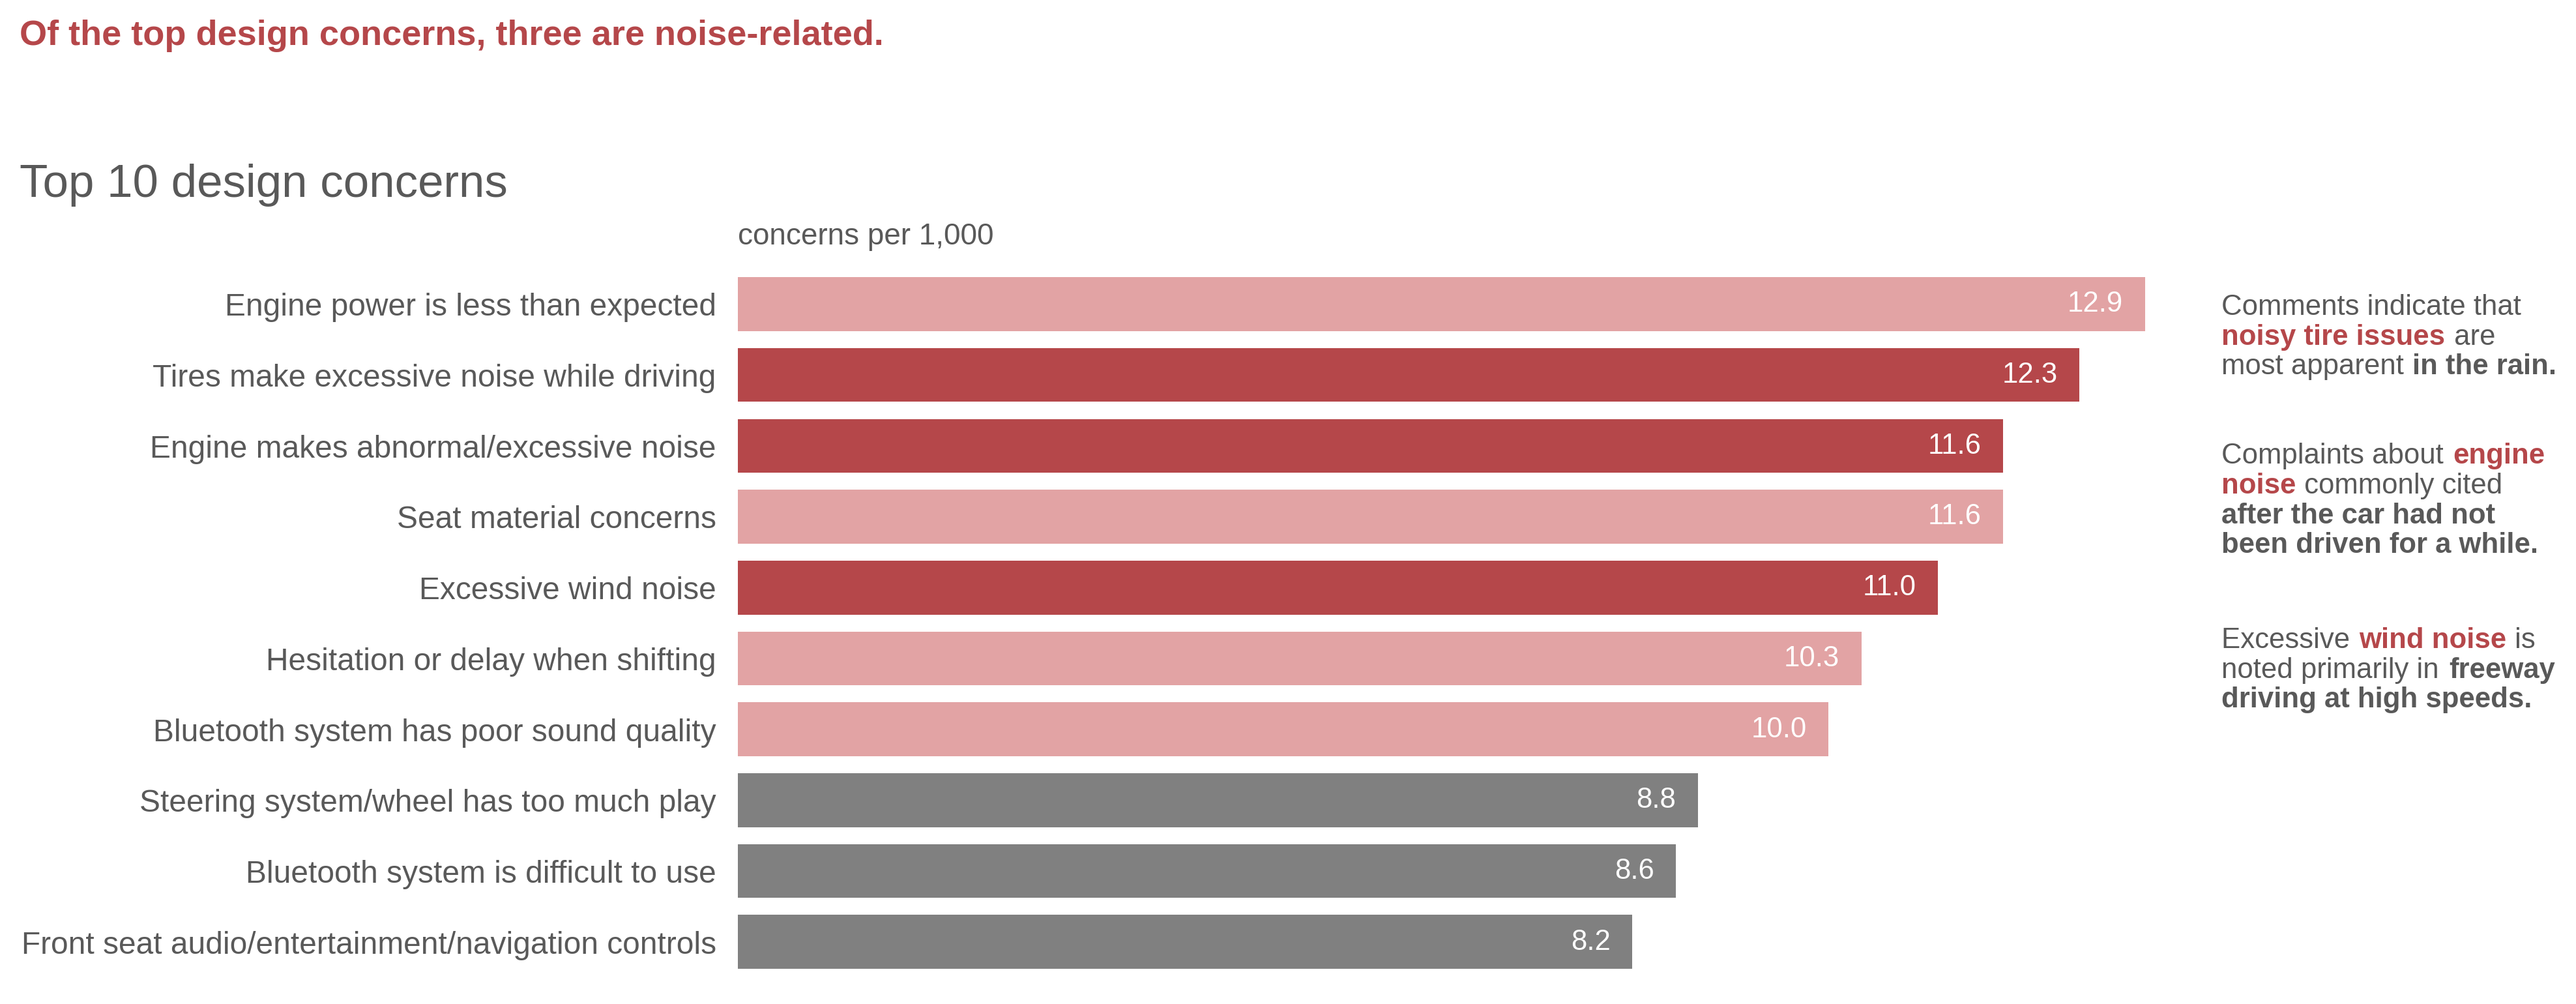 


---
## Design Principles - Part II: Scatter & Bubble Design

**When to use a scatter plot:**
- Relationship between two continuous variables
- Looking for correlation, clusters, or outliers

**When to use a bubble chart:**
- Same as scatter, but you have a **third numerical variable** to encode as size
- Size should be on a meaningful scale (set `size_max` to control)

**Scatter design rules:**
- Always ask: is the relationship actually meaningful, or spurious? 
- Remember: correlation IS NOT causation
- Add a reference line (average, trend) to give context
- Colour should encode a categorical variable — not continuous data
- Label outliers or notable points directly, not every point
- Beware overplotting (many overlapping dots) — use opacity or using a log scale on the x-axis or y-axis


---
## Let's Code Some Examples 💻 


In [1]:
import pandas as pd
import plotly.express as px

# Dataset: Gapminder 2007 — GDP, Life Expectancy, Population by Country

df = px.data.gapminder(year=2007)
print(f"Loaded: {len(df)} rows")
print(df.head())

Loaded: 142 rows
        country continent  year  lifeExp       pop     gdpPercap iso_alpha  \
11  Afghanistan      Asia  2007   43.828  31889923    974.580338       AFG   
23      Albania    Europe  2007   76.423   3600523   5937.029526       ALB   
35      Algeria    Africa  2007   72.301  33333216   6223.367465       DZA   
47       Angola    Africa  2007   42.731  12420476   4797.231267       AGO   
59    Argentina  Americas  2007   75.320  40301927  12779.379640       ARG   

    iso_num  
11        4  
23        8  
35       12  
47       24  
59       32  


### Example 1 — Basic scatter: GDP vs Life Expectancy

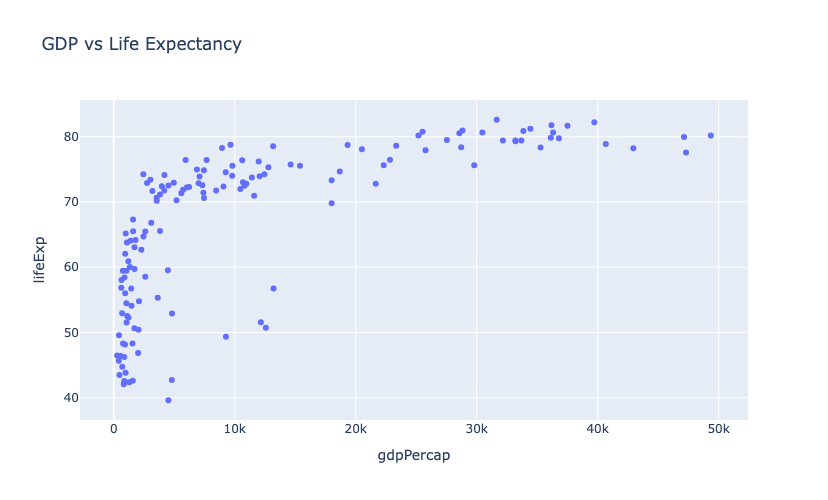

In [2]:

fig = px.scatter(data_frame=df, x='gdpPercap', y='lifeExp',
                 title='GDP vs Life Expectancy', height=500)
fig.show()


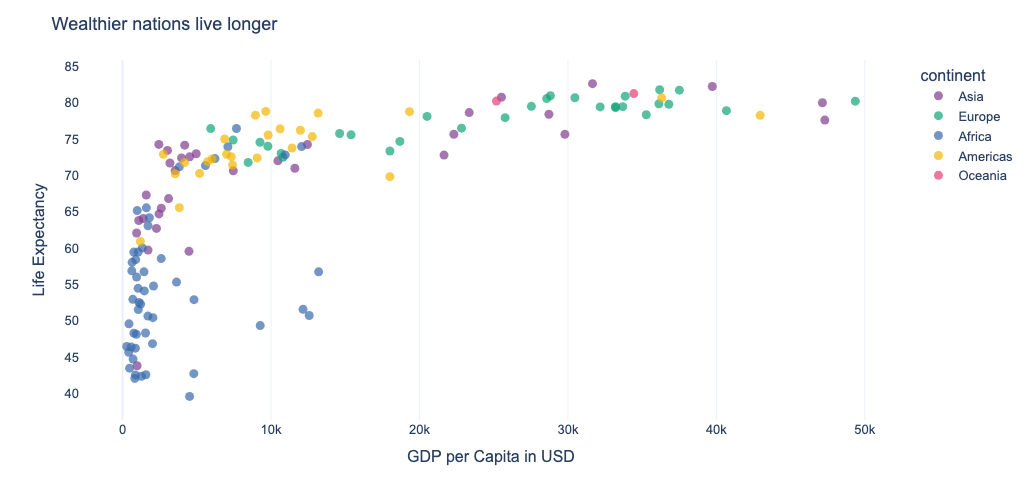

In [6]:
# Let's improve it!!
fig = px.scatter(
    data_frame=df, x='gdpPercap', y='lifeExp',
    color='continent',                      # colour encodes category (continent)
    hover_name='country',# hover shows country name
    hover_data={'continent':False},
    labels={'gdpPercap': 'GDP per Capita in USD',
            'lifeExp': 'Life Expectancy'},
    template='plotly_white',
    color_discrete_sequence=px.colors.qualitative.Bold  # plotly express 
)
fig.update_layout(
    title='Wealthier nations live longer',
    font=dict(family='Arial', size=13),
    xaxis=dict(showgrid=True),
    yaxis=dict(showgrid=False),
    height=500
)

fig.update_traces(marker=dict(size=9, opacity=0.7))
fig.show()



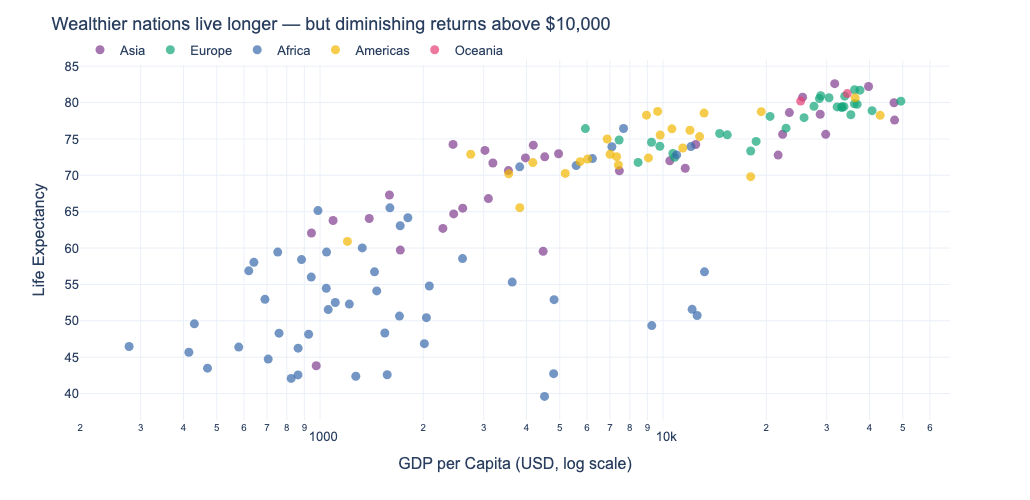

In [11]:
# Let's improve it further!!

fig = px.scatter(
    data_frame=df, x='gdpPercap', y='lifeExp',
    color='continent',                     
    hover_name='country',
    hover_data={'continent':False},
    log_x=True,                             # log scale: wealth is non-linear
    labels={'gdpPercap': 'GDP per Capita (USD, log scale)',
            'lifeExp': 'Life Expectancy'},
    color_discrete_sequence=px.colors.qualitative.Bold,
    template='plotly_white'
)
fig.update_layout(
    title='Wealthier nations live longer — but diminishing returns above $10,000',
    font=dict(family='Arial', size=13),
    height=500,
    legend=dict(orientation='h', x=0, y=1.07, title='')
)
fig.update_traces(marker=dict(size=9, opacity=0.7))
fig.show()

### Example 2 — Bubble chart: add population as size

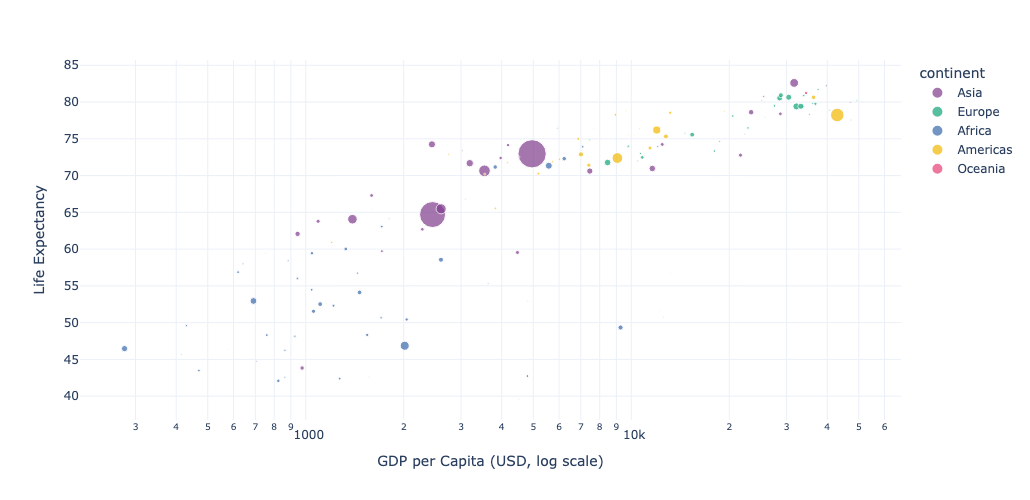

In [12]:

fig = px.scatter(data_frame=df, 
                 x='gdpPercap',
                 y='lifeExp',
                 size='pop', # must be a continuous numerical column
                 color='continent',                    
                 hover_name='country',
                 hover_data={'continent':False},
                 log_x=True,                             # log scale: wealth is non-linear
                 labels={'gdpPercap': 'GDP per Capita (USD, log scale)', 'lifeExp': 'Life Expectancy'},
                 color_discrete_sequence=px.colors.qualitative.Bold, 
                  template='plotly_white',
                 height=500)

fig.show()


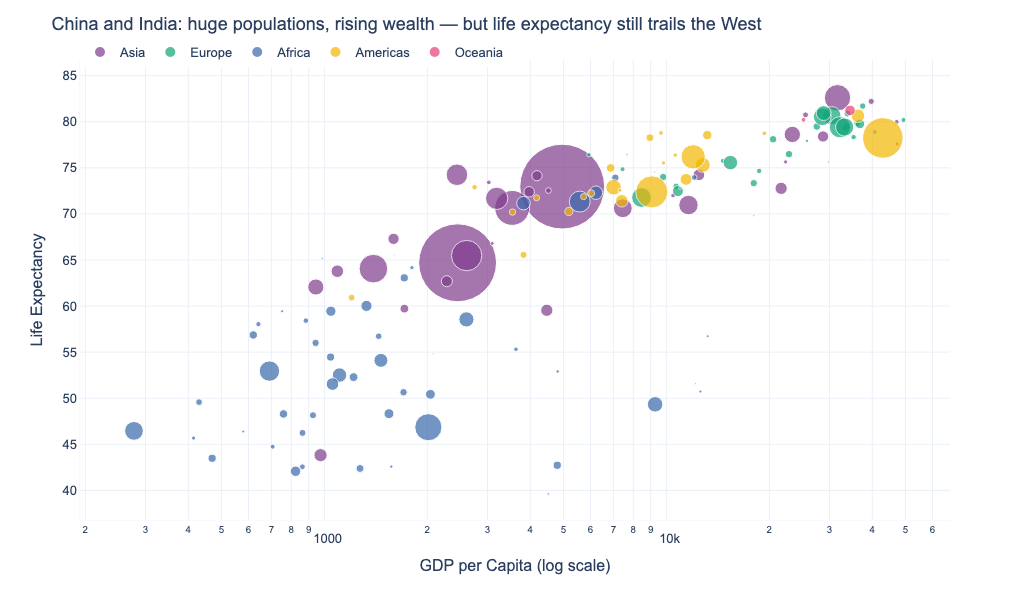

In [14]:
# Let's improve it

fig = px.scatter(
    data_frame=df, x='gdpPercap', y='lifeExp',
    size='pop',
    color='continent',
    hover_name='country',
    hover_data={'continent':False},
    log_x=True,
    size_max=60, # cap bubble size so small countries still visible; in pixels
    labels={'gdpPercap': 'GDP per Capita (log scale)', 'lifeExp': 'Life Expectancy', 'pop': 'Population'},
    template='plotly_white',
    color_discrete_sequence=px.colors.qualitative.Bold,
    custom_data=['country', 'pop'],
    opacity=0.7
)

# Improve hover: show formatted population using HTML
fig.update_traces(
    hovertemplate='<b>%{hovertext}</b><br>'
                  'GDP per capita: $%{x:,.0f}<br>'
                  'Life expectancy: %{y:.1f} yrs<br>'
                  'Population: %{customdata[1]:,.0f}')

fig.update_layout(
    title='China and India: huge populations, rising wealth — but life expectancy still trails the West',
    font=dict(family='Arial', size=13),
    yaxis=dict(linewidth=0.5),
    xaxis=dict(linewidth=0.5),
    height=600, width=1100,
    legend=dict(orientation='h', x=0, y=1.05, title='')
)
fig.show()


In [ ]:
px.colors.qualitative.Bold

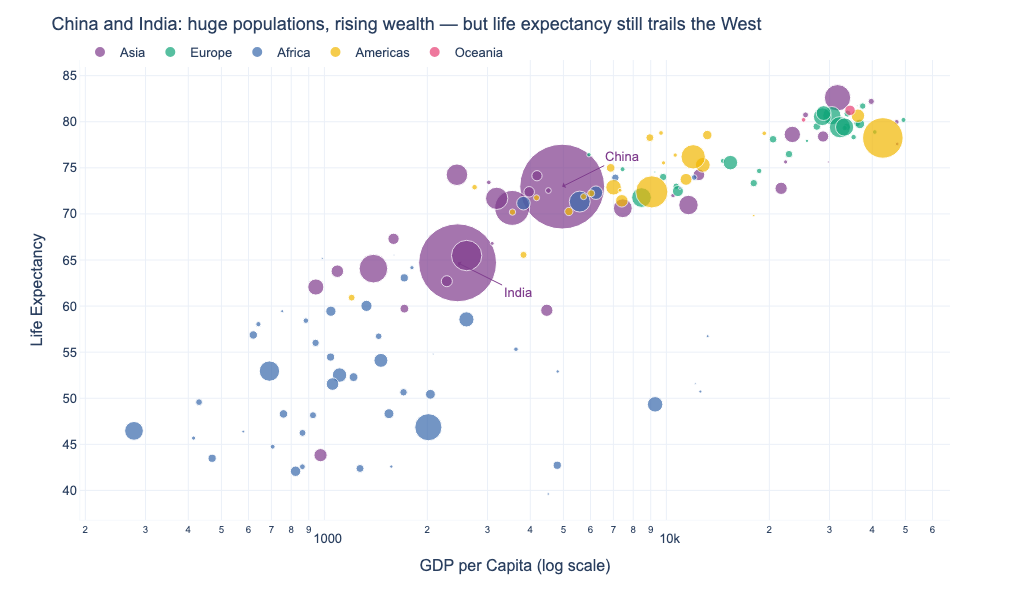

In [15]:
# let's improve it further!

# add annotation to highlight the insight
import math

for country, ax, ay in [('China', 60, -30), ('India', 60, 30)]:
    row = df[df['country'] == country].iloc[0]
    fig.add_annotation(
        x=math.log10(row['gdpPercap']), y=row['lifeExp'],
        text=f'{country}', 
        showarrow=True, arrowcolor='rgb(127, 60, 141)', arrowhead=1, ax=ax, ay=ay,
        font=dict(size=13, family='Arial', color='rgb(127, 60, 141)')
    )
    
fig.show()

### Example 3 — Grey + highlight on scatter: tell ONE story - The Inequality Story

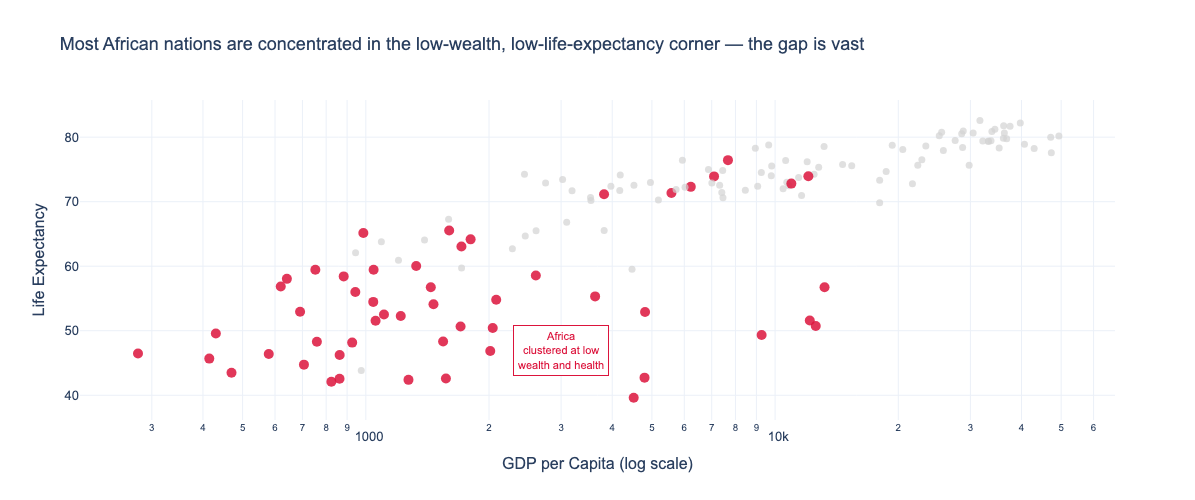

In [16]:


highlight_continent = 'Africa'
colour_map = {c: ('crimson' if c == highlight_continent else 'lightgrey') for c in df['continent'].unique()}

fig = px.scatter(
    data_frame=df,
    x='gdpPercap', y='lifeExp',
    color='continent',
    color_discrete_map=colour_map,
    hover_name='country',
    template='plotly_white',
    log_x=True,
    labels={'gdpPercap': 'GDP per Capita (log scale)', 'lifeExp': 'Life Expectancy', 'continent': ''},
    title='Most African nations are concentrated in the low-wealth, low-life-expectancy corner — the gap is vast'
)


fig.update_traces(
    selector=dict(name=highlight_continent),
    marker=dict(size=10, opacity=0.85)
)
fig.update_traces(
    selector=lambda t: t.name != highlight_continent,
    marker=dict(size=7, opacity=0.7)
)

fig.add_annotation(
    x=math.log10(3000), y=47,
    text='Africa<br>clustered at low<br>wealth and health',
    showarrow=False,
    font=dict(color='crimson', size=11, family='Arial'),
    bgcolor='white', bordercolor='crimson', borderwidth=1, borderpad=4
)

fig.update_layout(
    font=dict(family='Arial', size=13),
    showlegend=False,
    height=500
)

fig.show()


---
## Class Exercise 💪 💻


**Remember:**
- To highlight a group among multiple groups, grey all except the one you are highlighting
- Bubble size: always set `size_max` to prevent giant bubbles
- Log x-axis or y-axis for non-linear relationships
- Label outliers/notable points directly
